# 09_03 Naive Bayes: a Spam Filter from Bayes' Rule

**Learning objectives**
- Derive the **naive Bayes classifier** from Bayes' rule and the conditional-independence assumption, and compute it in **log space** with a **log-odds** score.
- Fit **Multinomial**, **Bernoulli** and **Gaussian** naive Bayes from scratch and know which one fits which kind of feature.
- Show that **Laplace smoothing** is a **Dirichlet prior** (Module 07) and study its effect on a real data set, the **SMS Spam Collection** (5,574 messages).
- Evaluate with a confusion matrix, **precision/recall**, **ROC/AUC**, and choose a decision threshold from the costs of the two errors; see why naive Bayes ranks well but is **over-confident**.

**Prerequisites:** [07_01 Bayesian updating](../../module_07_bayesian/notebooks/07_01_bayesian_updating_conjugates.ipynb), [01_05 Multinomial](../../module_01_discrete/notebooks/01_06_multinomial.ipynb), [09_02 GLMs](09_02_glms.ipynb), [00_05 Bayes' rule](../../module_00_foundations/notebooks/00_05_bayes_theorem.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
**Bayes' rule:** $P(c\mid x)=\dfrac{P(x\mid c)P(c)}{P(x)}$. A Multinomial$(n;\theta)$ counts how often each of $V$ outcomes occurs in $n$ draws; its MLE is $\hat\theta_j=n_j/n$. A Dirichlet$(\alpha)$ prior on $\theta$ is conjugate: the posterior mean is $(n_j+\alpha)/(n+V\alpha)$ (07_01).

## 3. Intuition and story
A message arrives: *"WINNER!! Claim your free prize, call 09061701461 now"*. Each word is a little bit of evidence: "free", "prize", "claim" and "call" are far more common in spam than in ordinary chat, "lol" and "ok" the other way round. Naive Bayes **adds up the evidence word by word** as if the words were independent given the class. The independence is false (words come in phrases) yet the sum of log-evidence is a surprisingly good ranking of messages from "ham" to "spam", and training takes one pass over the data: just count words in each class.

## 4. Formal definitions

For a document $x$ with word counts $(x_1,\dots,x_V)$ and classes $c\in\{\text{ham},\text{spam}\}$:

$$P(c\mid x)\ \propto\ P(c)\prod_{j=1}^{V}P(w_j\mid c)^{x_j}\quad\Rightarrow\quad \ln\frac{P(\text{spam}\mid x)}{P(\text{ham}\mid x)}=\underbrace{\ln\frac{P(\text{spam})}{P(\text{ham})}}_{\text{prior log-odds}}+\sum_jx_j\underbrace{\ln\frac{\theta_{j,\text{spam}}}{\theta_{j,\text{ham}}}}_{\text{weight of word }j}.$$

| Variant | Feature model | Estimate |
|---|---|---|
| **Multinomial** | word counts $x_j$ | $\hat\theta_{jc}=\dfrac{N_{jc}+\alpha}{N_c+\alpha V}$ |
| **Bernoulli** | word present or not | $\hat p_{jc}=\dfrac{d_{jc}+\alpha}{D_c+2\alpha}$ and the absent words also count: $\sum_j\ln(1-p_{jc})$ |
| **Gaussian** | continuous feature | $x_j\mid c\sim N(\mu_{jc},\sigma_{jc}^2)$ with sample mean and variance |

$N_{jc}$ is the number of times word $j$ appears in the training documents of class $c$, $N_c=\sum_jN_{jc}$, $D_{jc}$ the number of class-$c$ documents containing it. The classifier predicts spam when the log-odds exceed a **threshold** $t$ ($t=0$ for equal costs).

## 5. Derivations

### 5.1 From Bayes' rule to a sum of weights
The denominator $P(x)$ is the same for both classes, so in the log-odds it cancels. Under the "naive" assumption the likelihood factorises: $P(x\mid c)=\prod_jP(w_j\mid c)^{x_j}$ (up to a multinomial coefficient that is also equal for both classes). Taking logs turns the product into the sum above. **In plain words.** Each word contributes a fixed vote $\ln(\theta_{j,\text{spam}}/\theta_{j,\text{ham}})$ every time it appears; the message score is the prior log-odds plus the sum of the votes. Positive votes ("free" +2.5) say spam, negative votes ("lol" -2) say ham.

### 5.2 Why logs
A message of 20 words multiplies 20 probabilities of size $10^{-3}$; the product, $10^{-60}$, underflows for long documents. Sums of logs do not. **In plain words.** Never multiply many small probabilities; add their logarithms.

### 5.3 Laplace smoothing is a Dirichlet prior
Without smoothing a word never seen in spam training has $\theta_{j,\text{spam}}=0$ and a single occurrence makes $P(\text{spam}\mid x)=0$ whatever the rest says. With a Dirichlet$(\alpha,\dots,\alpha)$ prior, the posterior mean of $\theta_c$ is $(N_{jc}+\alpha)/(N_c+\alpha V)$, i.e. $\alpha$ **pseudo-counts** per word (07_01). **In plain words.** Smoothing says "before reading any messages I act as if I had seen every word $\alpha$ times in each class"; $\alpha=1$ is Laplace's rule, small $\alpha$ trusts the data more.

### 5.4 Naive Bayes against logistic regression
Multinomial naive Bayes has the linear log-odds form $b+\sum_jw_jx_j$, exactly the form of logistic regression (09_02). The difference is how the weights are fitted: naive Bayes by counting (a **generative** model of $x$ given $c$), logistic regression by maximising the conditional likelihood of $c$ given $x$ (**discriminative**). **In plain words.** Same shape of decision rule, different training; naive Bayes is faster and needs less data, logistic regression is usually more accurate when there is enough data.

### 5.5 Over-confidence
Counting the same evidence twice (a phrase "free prize" contributes two correlated votes) makes the log-odds too large in absolute value, so the probabilities are pushed towards 0 and 1. **In plain words.** The ranking is trustworthy, the probabilities are not; recalibrate before using them as risks (08_01, 09_02).

## 6. Properties and relationships
- **Fast and incremental:** training is counting; new data update the counts without refitting.
- **Works with few data and many features** (text, genes) because it estimates $V$ one-dimensional distributions instead of a joint.
- **Linear decision rule** in the word counts; the weight of each word is interpretable.
- **Errors of independence cancel partly in ranking** but inflate the confidence; the decision threshold should be tuned on held-out data.
- **Variants:** Multinomial for counts (documents), Bernoulli for presence/absence (short texts, binary features), Gaussian for continuous features, complement NB for imbalanced text.
- **Link to ML and AI:** the baseline for text classification, spam and sentiment filters, medical decision support; the generative view leads to Gaussian mixtures (09_04), VAEs (09_08) and, as a thought, the next-token factorisation of language models.

## 7. Data and a naive Bayes from scratch

The SMS Spam Collection is read from `../data/SMSSpamCollection.tsv`. Messages are lower-cased and split into word tokens; the vocabulary keeps tokens seen at least twice in the training part.

In [2]:
import re
from collections import Counter
from scipy import sparse
from scipy.stats import rankdata
raw = pd.read_csv("../data/SMSSpamCollection.tsv", sep="\t", header=None, names=["label", "text"], encoding="utf-8", quoting=3); y_all = (raw["label"] == "spam").astype(int).to_numpy(); texts = raw["text"].tolist()
tok = lambda s: re.findall(r"[a-z0-9']+|[£$!?]", s.lower())
g = np.random.default_rng(0); perm = g.permutation(len(texts)); ntr = int(0.8 * len(texts)); itr, ite = perm[:ntr], perm[ntr:]
cnt = Counter(w for i in itr for w in tok(texts[i])); vocab = {w: k for k, (w, c) in enumerate(sorted((w, c) for w, c in cnt.items() if c >= 2))}; V = len(vocab)
def bow(idx):
    rows, cols, vals = [], [], []
    for r, i in enumerate(idx):
        for w, c in Counter(tok(texts[i])).items():
            if w in vocab: rows.append(r); cols.append(vocab[w]); vals.append(c)
    return sparse.csr_matrix((vals, (rows, cols)), shape=(len(idx), V), dtype=float)
Xtr, Xte = bow(itr), bow(ite); ytr, yte = y_all[itr], y_all[ite]; words = np.array(sorted(vocab, key=vocab.get))
print(f"messages {len(texts)}, spam {y_all.sum()} ({y_all.mean():.4f}) | train {ntr}, test {len(ite)} | vocabulary {V} | spam share train {ytr.mean():.4f}, test {yte.mean():.4f}")
class MNB:
    def __init__(self, alpha=1.0): self.alpha = alpha
    def fit(self, X, y):
        self.cc = np.array([(y == 0).sum(), (y == 1).sum()]); self.logprior = np.log(self.cc / self.cc.sum()); fc = np.vstack([np.asarray(X[y == c].sum(axis=0)).ravel() for c in (0, 1)]); self.fc = fc
        self.logtheta = np.log((fc + self.alpha) / (fc.sum(axis=1, keepdims=True) + self.alpha * X.shape[1])); return self
    def logodds(self, X): return np.asarray(X @ (self.logtheta[1] - self.logtheta[0])).ravel() + self.logprior[1] - self.logprior[0]
def auc(score, y): r = rankdata(score); n1 = y.sum(); n0 = len(y) - n1; return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def metrics(score, y, t=0.0):
    pred = score > t; tp = np.sum(pred & (y == 1)); fp = np.sum(pred & (y == 0)); fn = np.sum(~pred & (y == 1)); tn = np.sum(~pred & (y == 0)); pr = tp / max(tp + fp, 1); rc = tp / max(tp + fn, 1)
    return dict(tp=tp, fp=fp, fn=fn, tn=tn, accuracy=(tp + tn) / len(y), precision=pr, recall=rc, f1=2 * pr * rc / max(pr + rc, 1e-12), fpr=fp / max(fp + tn, 1))
m1 = MNB(1.0).fit(Xtr, ytr); s_te = m1.logodds(Xte); mm = metrics(s_te, yte); print({k: round(float(v), 4) for k, v in mm.items()}, "AUC", round(auc(s_te, yte), 4))
assert V > 3000 and abs(y_all.mean() - 747 / 5574) < 1e-12 and mm["accuracy"] > 0.95 and auc(s_te, yte) > 0.98

messages 5574, spam 747 (0.1340) | train 4459, test 1115 | vocabulary 3817 | spam share train 0.1359, test 0.1265
{'tp': 131.0, 'fp': 5.0, 'fn': 10.0, 'tn': 969.0, 'accuracy': 0.9865, 'precision': 0.9632, 'recall': 0.9291, 'f1': 0.9458, 'fpr': 0.0051} AUC 0.9823


## 8. 2D visuals

### 8.1 The data: class balance and message length
Spam is 13.4 % of the messages. Spam messages are longer and use more digits than ham (they carry phone numbers and prices).

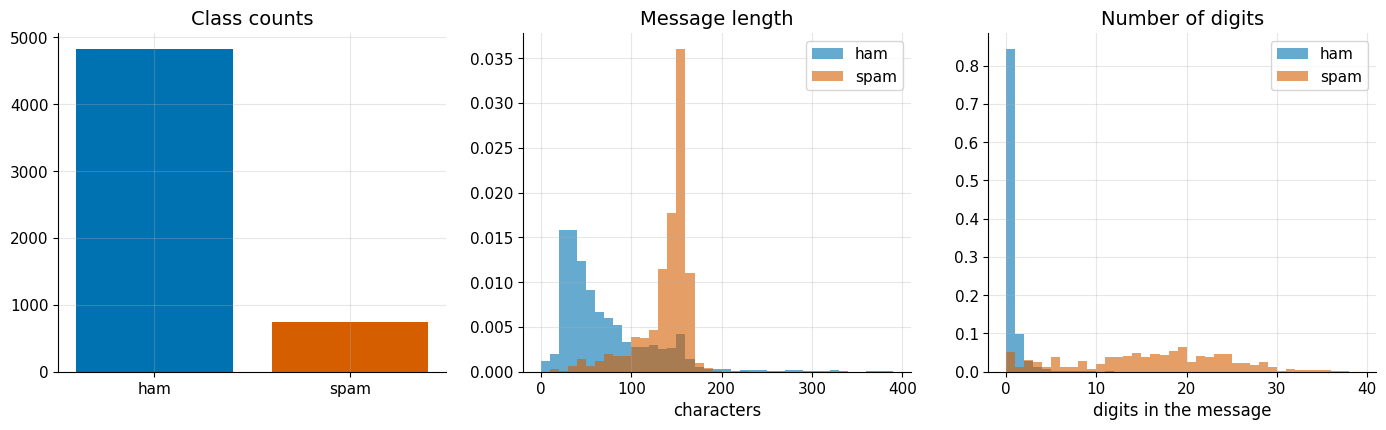

mean length: ham 71.5, spam 138.7 | mean digits: ham 0.31, spam 15.81


In [3]:
ln_ = np.array([len(t) for t in texts]); dg = np.array([sum(c.isdigit() for c in t) for t in texts]); fig, axes = plt.subplots(1, 3, figsize=(17, 4.4)); axes[0].bar(["ham", "spam"], [(y_all == 0).sum(), (y_all == 1).sum()], color=[MAIN, HIGHLIGHT]); axes[0].set_title("Class counts");
for c, colr, nm in [(0, MAIN, "ham"), (1, HIGHLIGHT, "spam")]: axes[1].hist(ln_[y_all == c], bins=np.arange(0, 400, 10), density=True, alpha=0.6, color=colr, label=nm); axes[2].hist(dg[y_all == c], bins=np.arange(0, 40, 1), density=True, alpha=0.6, color=colr, label=nm)
axes[1].set_xlabel("characters"); axes[1].legend(); axes[1].set_title("Message length"); axes[2].set_xlabel("digits in the message"); axes[2].legend(); axes[2].set_title("Number of digits")
plt.show(); print(f"mean length: ham {ln_[y_all == 0].mean():.1f}, spam {ln_[y_all == 1].mean():.1f} | mean digits: ham {dg[y_all == 0].mean():.2f}, spam {dg[y_all == 1].mean():.2f}"); assert ln_[y_all == 1].mean() > ln_[y_all == 0].mean() + 30 and dg[y_all == 1].mean() > 5 * dg[y_all == 0].mean()

### 8.2 What the model learned: the words with the largest votes
The weight of a word is $\ln(\theta_{j,\text{spam}}/\theta_{j,\text{ham}})$; only words seen at least 15 times are shown.

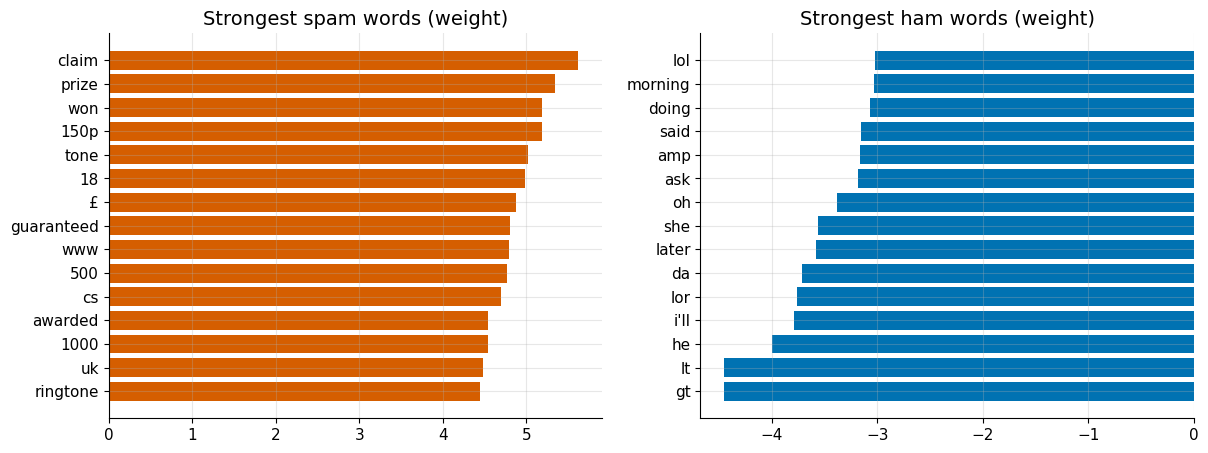

top spam words: [np.str_('claim'), np.str_('prize'), np.str_('won'), np.str_('150p'), np.str_('tone'), np.str_('18'), np.str_('£'), np.str_('guaranteed')] | top ham words: [np.str_('gt'), np.str_('lt'), np.str_('he'), np.str_("i'll"), np.str_('lor'), np.str_('da'), np.str_('later'), np.str_('she')]


In [4]:
w_ = m1.logtheta[1] - m1.logtheta[0]; tot = m1.fc.sum(axis=0); ok = np.where(tot >= 15)[0]; top = ok[np.argsort(w_[ok])[::-1][:15]]; bot = ok[np.argsort(w_[ok])[:15]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5)); axes[0].barh(words[top][::-1], w_[top][::-1], color=HIGHLIGHT); axes[0].set_title("Strongest spam words (weight)"); axes[1].barh(words[bot], w_[bot], color=MAIN); axes[1].set_title("Strongest ham words (weight)")
plt.show(); print("top spam words:", list(words[top][:8]), "| top ham words:", list(words[bot][:8])); assert w_[top].min() > 1.5 and w_[bot].max() < -1.0

### 8.3 The two score distributions and the threshold
The log-odds of the test messages: ham scores pile up far below zero, spam scores far above, with a small overlap. The decision threshold slides along this axis.

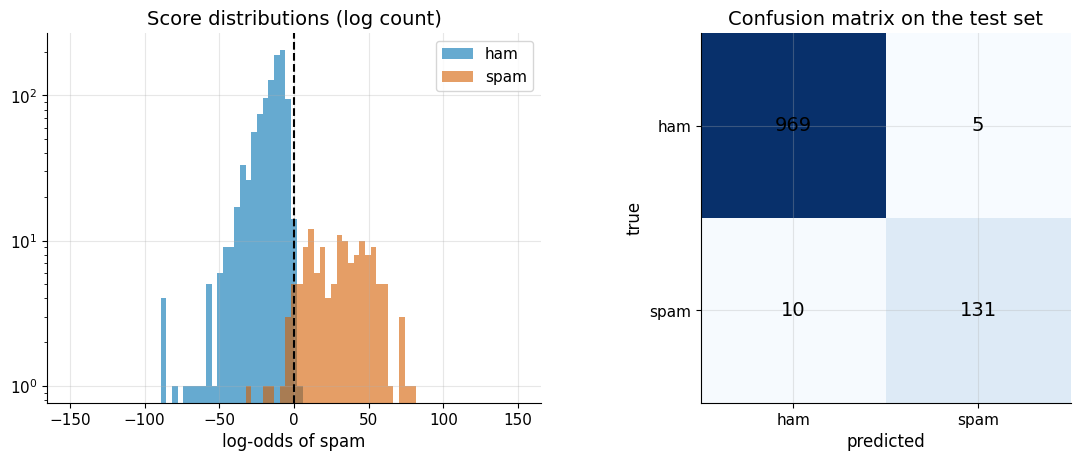

median log-odds: ham -12.8 spam 31.5


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8)); bins_ = np.linspace(-150, 150, 80); axes[0].hist(s_te[yte == 0], bins=bins_, color=MAIN, alpha=0.6, label="ham"); axes[0].hist(s_te[yte == 1], bins=bins_, color=HIGHLIGHT, alpha=0.6, label="spam"); axes[0].axvline(0, color="black", linestyle="--"); axes[0].set_xlabel("log-odds of spam"); axes[0].legend(); axes[0].set_yscale("log"); axes[0].set_title("Score distributions (log count)")
cm = np.array([[mm["tn"], mm["fp"]], [mm["fn"], mm["tp"]]]); im = axes[1].imshow(cm, cmap="Blues"); axes[1].set_xticks([0, 1]); axes[1].set_yticks([0, 1]); axes[1].set_xticklabels(["ham", "spam"]); axes[1].set_yticklabels(["ham", "spam"]); axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true"); axes[1].set_title("Confusion matrix on the test set")
for i in range(2):
    for j in range(2): axes[1].text(j, i, int(cm[i, j]), ha="center", va="center", color="black", fontsize=14)
plt.show(); print("median log-odds: ham", np.median(s_te[yte == 0]).round(1), "spam", np.median(s_te[yte == 1]).round(1)); assert np.median(s_te[yte == 0]) < -5 and np.median(s_te[yte == 1]) > 5

## 9. 3D visuals

### 9.1 Static: test F1 over (smoothing $\alpha$, training-set fraction)
More training data helps, and the smoothing constant has a broad optimum at small values: with large $\alpha$ the pseudo-counts drown the real counts.

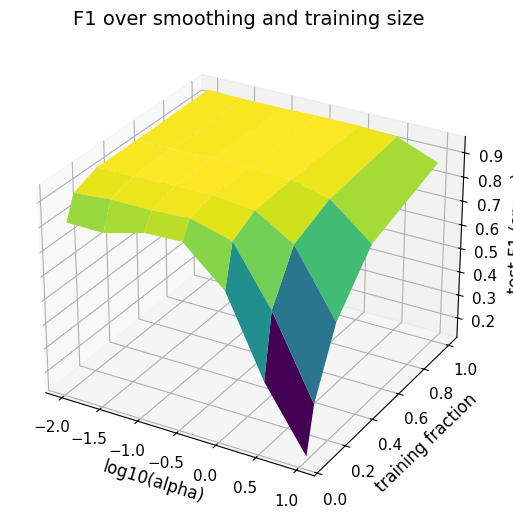

       0.01   0.03    0.1    0.3    1.0    3.0   10.0
0.05  0.809  0.808  0.852  0.858  0.709  0.389  0.132
0.10  0.905  0.919  0.919  0.928  0.882  0.651  0.321
0.25  0.942  0.943  0.950  0.950  0.933  0.840  0.576
0.50  0.941  0.945  0.949  0.950  0.942  0.905  0.769
1.00  0.945  0.942  0.942  0.946  0.946  0.938  0.872


In [6]:
alphas = np.array([0.01, 0.03, 0.1, 0.3, 1, 3, 10]); fracs = np.array([0.05, 0.1, 0.25, 0.5, 1.0]); F1 = np.zeros((len(fracs), len(alphas)))
for i, f in enumerate(fracs):
    sub = np.random.default_rng(10 + i).permutation(ntr)[:int(f * ntr)]
    for j, a in enumerate(alphas): F1[i, j] = metrics(MNB(a).fit(Xtr[sub], ytr[sub]).logodds(Xte), yte)["f1"]
Ag, Fg = np.meshgrid(np.log10(alphas), fracs); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Ag, Fg, F1, cmap="viridis", edgecolor="none"); ax.set_xlabel("log10(alpha)"); ax.set_ylabel("training fraction"); ax.set_zlabel("test F1 (spam)"); ax.set_title("F1 over smoothing and training size"); ax.view_init(elev=28, azim=-60)
plt.show(); print(pd.DataFrame(F1.round(3), index=[f"{f:.2f}" for f in fracs], columns=[str(a) for a in alphas]).to_string()); assert F1[-1].max() > F1[0].max() and F1[-1, -1] < F1[-1].max()

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=np.log10(alphas), y=fracs, z=F1, colorscale="Viridis")); fig.update_layout(title="Test F1", width=760, height=560, scene=dict(xaxis_title="log10 alpha", yaxis_title="training fraction", zaxis_title="F1")); fig.show()

### 9.3 Static: a Gaussian naive Bayes in two dimensions
For two continuous features (message length and number of digits) each class is modelled as a Gaussian with independent coordinates (axis-aligned ellipses). The surface is the density of each class weighted by its prior.

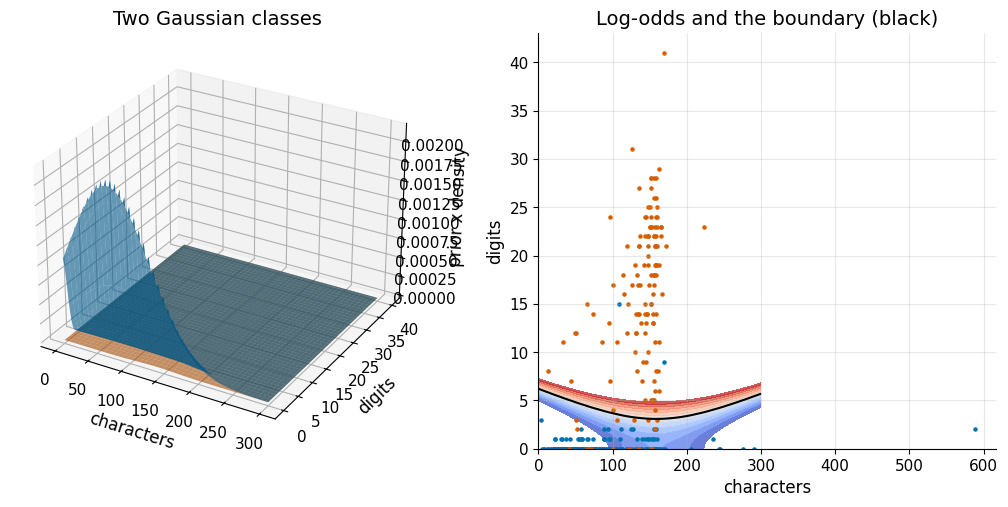

Gaussian NB with 2 features: AUC 0.9765 accuracy 0.9758


In [8]:
F = np.column_stack([ln_, dg]).astype(float); Ftr, Fte = F[itr], F[ite]; gmu = np.array([Ftr[ytr == c].mean(axis=0) for c in (0, 1)]); gsd = np.array([Ftr[ytr == c].std(axis=0) for c in (0, 1)]); gpri = np.array([(ytr == 0).mean(), (ytr == 1).mean()])
LG, DG = np.meshgrid(np.linspace(0, 300, 90), np.linspace(0, 40, 90)); dens = [gpri[c] * stats.norm.pdf(LG, gmu[c, 0], gsd[c, 0]) * stats.norm.pdf(DG, gmu[c, 1], gsd[c, 1]) for c in (0, 1)]
fig = plt.figure(figsize=(13, 5.4)); ax = fig.add_subplot(1, 2, 1, projection="3d"); ax.plot_surface(LG, DG, dens[0], color=MAIN, alpha=0.6); ax.plot_surface(LG, DG, dens[1], color=HIGHLIGHT, alpha=0.6); ax.set_xlabel("characters"); ax.set_ylabel("digits"); ax.set_zlabel("prior x density"); ax.set_title("Two Gaussian classes"); ax.view_init(elev=28, azim=-60)
ax2 = fig.add_subplot(1, 2, 2); ax2.contourf(LG, DG, np.log(dens[1] / dens[0]), levels=np.linspace(-6, 6, 13), cmap="coolwarm", alpha=0.8); ax2.contour(LG, DG, np.log(dens[1] / dens[0]), levels=[0], colors="black"); ax2.scatter(Fte[yte == 0][:300, 0], Fte[yte == 0][:300, 1], s=5, color=MAIN); ax2.scatter(Fte[yte == 1][:150, 0], Fte[yte == 1][:150, 1], s=5, color=HIGHLIGHT); ax2.set_xlabel("characters"); ax2.set_ylabel("digits"); ax2.set_title("Log-odds and the boundary (black)")
plt.show(); gs_te = np.sum(stats.norm.logpdf(Fte[:, None, :], gmu[None], gsd[None]), axis=2); lo_g = gs_te[:, 1] - gs_te[:, 0] + np.log(gpri[1] / gpri[0]); print("Gaussian NB with 2 features: AUC", round(auc(lo_g, yte), 4), "accuracy", round(metrics(lo_g, yte)["accuracy"], 4)); assert auc(lo_g, yte) > 0.85

## 10. Simulation vs theory

### 10.1 Naive Bayes is exact when the independence assumption is true
Generate data from a naive Bayes model itself (3 classes' word probabilities, known) and compare the classifier's accuracy with the **Bayes-optimal** accuracy computed with the true parameters. With $n$ training messages the fitted classifier approaches the optimum.

In [9]:
g = np.random.default_rng(3); Vs = 50; th = g.dirichlet(np.ones(Vs) * 2, 2); L = 12; true_w = np.log(th[1]) - np.log(th[0])
def gen(n): yy = (g.random(n) < 0.3).astype(int); return np.vstack([g.multinomial(L, th[c]) for c in yy]), yy
Xt, yt = gen(20_000); opt = metrics(Xt @ true_w + np.log(0.3 / 0.7), yt)["accuracy"]; rows = []
for n_ in (20, 100, 500, 5000): Xs, ys = gen(n_); rows.append((n_, metrics(MNB(0.5).fit(sparse.csr_matrix(Xs), ys).logodds(sparse.csr_matrix(Xt)), yt)["accuracy"]))
print("Bayes-optimal accuracy with the true parameters:", round(opt, 4)); print(pd.DataFrame(rows, columns=["training messages", "test accuracy"]).round(4).to_string(index=False)); assert rows[-1][1] > opt - 0.01 and rows[0][1] < rows[-1][1]

Bayes-optimal accuracy with the true parameters: 0.9524
 training messages  test accuracy
                20         0.8904
               100         0.9326
               500         0.9503
              5000         0.9524


### 10.2 Over-confidence by duplicated evidence
If every word is duplicated in the message (a fully dependent feature), the independence assumption double-counts it: the log-odds exactly double, the ranking and the decisions at threshold 0 do not change, but the probabilities become more extreme.

In [10]:
s1 = m1.logodds(Xte); s2 = m1.logodds(Xte * 2) - m1.logprior[1] + m1.logprior[0] + (m1.logprior[1] - m1.logprior[0]); lw = np.asarray(Xte @ (m1.logtheta[1] - m1.logtheta[0])).ravel(); pri = m1.logprior[1] - m1.logprior[0]
dbl = 2 * lw + pri; print(f"AUC single {auc(s1, yte):.4f}, duplicated {auc(dbl, yte):.4f} | accuracy at 0: {metrics(s1, yte)['accuracy']:.4f} vs {metrics(dbl, yte)['accuracy']:.4f} | mean |log-odds|: {np.abs(s1).mean():.1f} vs {np.abs(dbl).mean():.1f}")
p1 = 1 / (1 + np.exp(-np.clip(s1, -30, 30))); p2 = 1 / (1 + np.exp(-np.clip(dbl, -30, 30))); print("share of test messages with probability beyond 0.999 or below 0.001:", np.mean((p1 > 0.999) | (p1 < 0.001)).round(3), "vs", np.mean((p2 > 0.999) | (p2 < 0.001)).round(3)); assert abs(auc(s1, yte) - auc(dbl, yte)) < 0.01

AUC single 0.9823, duplicated 0.9823 | accuracy at 0: 0.9865 vs 0.9848 | mean |log-odds|: 18.2 vs 35.0
share of test messages with probability beyond 0.999 or below 0.001: 0.841 vs 0.938


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("fit: counts = X[y == c].sum(axis=0); theta = (counts + alpha) / (counts.sum() + alpha * V) | score: X @ (log_theta[1] - log_theta[0]) + log_prior_odds")
print("Gaussian NB: stats.norm.logpdf(x, mu_c, sd_c).sum(axis=1) + np.log(prior_c) | AUC = (rank sum of positives - n1 (n1 + 1) / 2) / (n1 n0)")
print("library equivalents: sklearn.naive_bayes.MultinomialNB(alpha=1), BernoulliNB, GaussianNB | log-sum-exp for probabilities: scipy.special.logsumexp")
from scipy.special import logsumexp
ls = np.array([[-1.0, -2.0], [-0.5, -3.0]]); print("posterior from log scores:", np.exp(ls - logsumexp(ls, axis=1, keepdims=True)).round(4), "(rows sum to 1)")
assert np.allclose(np.exp(ls - logsumexp(ls, axis=1, keepdims=True)).sum(axis=1), 1)

fit: counts = X[y == c].sum(axis=0); theta = (counts + alpha) / (counts.sum() + alpha * V) | score: X @ (log_theta[1] - log_theta[0]) + log_prior_odds
Gaussian NB: stats.norm.logpdf(x, mu_c, sd_c).sum(axis=1) + np.log(prior_c) | AUC = (rank sum of positives - n1 (n1 + 1) / 2) / (n1 n0)
library equivalents: sklearn.naive_bayes.MultinomialNB(alpha=1), BernoulliNB, GaussianNB | log-sum-exp for probabilities: scipy.special.logsumexp
posterior from log scores: [[0.7311 0.2689]
 [0.9241 0.0759]] (rows sum to 1)


## 12. Real-world worked examples

---
### Example 1 (main): the SMS spam filter

**Scenario.** 80 % of the 5,574 messages (4,459) train the model and 20 % (1,115) test it. We use Multinomial naive Bayes with $\alpha=1$.

**Questions**
1. What are the confusion matrix, accuracy, precision, recall and F1 on the test set? What accuracy would "always ham" get?
2. What is the ROC AUC, and what is the probability that a random spam message scores above a random ham message?
3. Which words carry the most evidence, and how is the score of one real spam message built word by word?
4. How well calibrated are the predicted probabilities?

### 12.1 By hand (one message)
Take the two-word message "free prize". Suppose $P(\text{free}\mid\text{spam})=0.8\,\%$, $P(\text{free}\mid\text{ham})=0.03\,\%$, $P(\text{prize}\mid\text{spam})=0.4\,\%$, $P(\text{prize}\mid\text{ham})=0.003\,\%$ and the prior odds are $0.134/0.866=0.155$. The log-odds are $\ln0.155+\ln\frac{0.8}{0.03}+\ln\frac{0.4}{0.003}=-1.87+3.28+4.89=6.30$: odds of 545 to 1 for spam, $P=0.998$.

In [12]:
base_acc = np.mean(yte == 0); print(f"Q1: always ham accuracy {base_acc:.4f}"); print(pd.DataFrame([{k: round(float(v), 4) for k, v in mm.items()}]).to_string(index=False)); a1 = auc(s_te, yte); print(f"Q2: AUC {a1:.4f}")
i_sp = int(np.where(yte == 1)[0][0]); doc = texts[ite[i_sp]]; xv = Xte[i_sp].toarray().ravel(); contrib = xv * (m1.logtheta[1] - m1.logtheta[0]); prior_lo = m1.logprior[1] - m1.logprior[0]; o = np.argsort(-np.abs(contrib))[:6]
print("Q3: message:", doc[:110]); print("prior log-odds", round(float(prior_lo), 3), "| word votes:", {words[k]: round(float(contrib[k]), 2) for k in o if contrib[k] != 0}, "| total log-odds", round(float(prior_lo + contrib.sum()), 2), "=", round(float(s_te[i_sp]), 2), "-> P(spam) =", round(float(1 / (1 + np.exp(-s_te[i_sp]))), 4))
p_hat = 1 / (1 + np.exp(-np.clip(s_te, -30, 30))); bins = np.array([0, 0.01, 0.1, 0.5, 0.9, 0.99, 1.0001]); cal = pd.DataFrame([{"predicted range": f"{bins[k]:.2f}-{bins[k + 1]:.2f}", "messages": int(((p_hat >= bins[k]) & (p_hat < bins[k + 1])).sum()), "mean predicted": p_hat[(p_hat >= bins[k]) & (p_hat < bins[k + 1])].mean() if ((p_hat >= bins[k]) & (p_hat < bins[k + 1])).any() else np.nan, "observed spam rate": yte[(p_hat >= bins[k]) & (p_hat < bins[k + 1])].mean() if ((p_hat >= bins[k]) & (p_hat < bins[k + 1])).any() else np.nan} for k in range(6)]); print("Q4:"); print(cal.round(4).to_string(index=False))

Q1: always ham accuracy 0.8735
   tp  fp   fn    tn  accuracy  precision  recall     f1    fpr
131.0 5.0 10.0 969.0    0.9865     0.9632  0.9291 0.9458 0.0051
Q2: AUC 0.9823
Q3: message: U have a secret admirer who is looking 2 make contact with U-find out who they R*reveal who thinks UR so speci
prior log-odds -1.85 | word votes: {np.str_('reveal'): 3.19, np.str_('admirer'): 3.06, np.str_('contact'): 2.57, np.str_('who'): 2.11, np.str_('so'): -1.82, np.str_('secret'): 1.67} | total log-odds 10.69 = 10.69 -> P(spam) = 1.0
Q4:
predicted range  messages  mean predicted  observed spam rate
      0.00-0.01       905          0.0004              0.0044
      0.01-0.10        55          0.0316              0.0182
      0.10-0.50        19          0.1967              0.2632
      0.50-0.90         6          0.7303              0.3333
      0.90-0.99         3          0.9449              1.0000
      0.99-1.00       127          0.9998              0.9921


### 12.2 Asserts

In [13]:
assert abs(np.log(0.134 / 0.866) + np.log(0.8 / 0.03) + np.log(0.4 / 0.003) - 6.30) < 0.02 and mm["tp"] + mm["fn"] == yte.sum() and mm["tp"] + mm["fp"] + mm["fn"] + mm["tn"] == len(yte)
assert mm["accuracy"] > base_acc + 0.08 and mm["recall"] > 0.9 and mm["precision"] > 0.9 and a1 > 0.98 and abs(prior_lo + contrib.sum() - s_te[i_sp]) < 1e-9
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
AUC is the probability that a random spam outranks a random ham: check with 200,000 random pairs, and the test-set confusion matrix against 200 bootstrap resamples of the test set.

In [14]:
g = np.random.default_rng(4); a_ = g.choice(s_te[yte == 1], 200_000); b_ = g.choice(s_te[yte == 0], 200_000); pa = np.mean(a_ > b_) + 0.5 * np.mean(a_ == b_); print(f"P(spam score > ham score) over 200,000 random pairs: {pa:.4f} | AUC {a1:.4f}")
boot = np.array([(lambda ix: metrics(s_te[ix], yte[ix])["f1"])(g.integers(0, len(yte), len(yte))) for _ in range(300)]); print(f"bootstrap F1: mean {boot.mean():.4f}, 95% interval ({np.quantile(boot, 0.025):.4f}, {np.quantile(boot, 0.975):.4f}) | observed {mm['f1']:.4f}"); assert abs(pa - a1) < 0.003 and np.quantile(boot, 0.025) < mm["f1"] < np.quantile(boot, 0.975)

P(spam score > ham score) over 200,000 random pairs: 0.9824 | AUC 0.9823
bootstrap F1: mean 0.9466, 95% interval (0.9189, 0.9701) | observed 0.9458


### 12.4 Plots

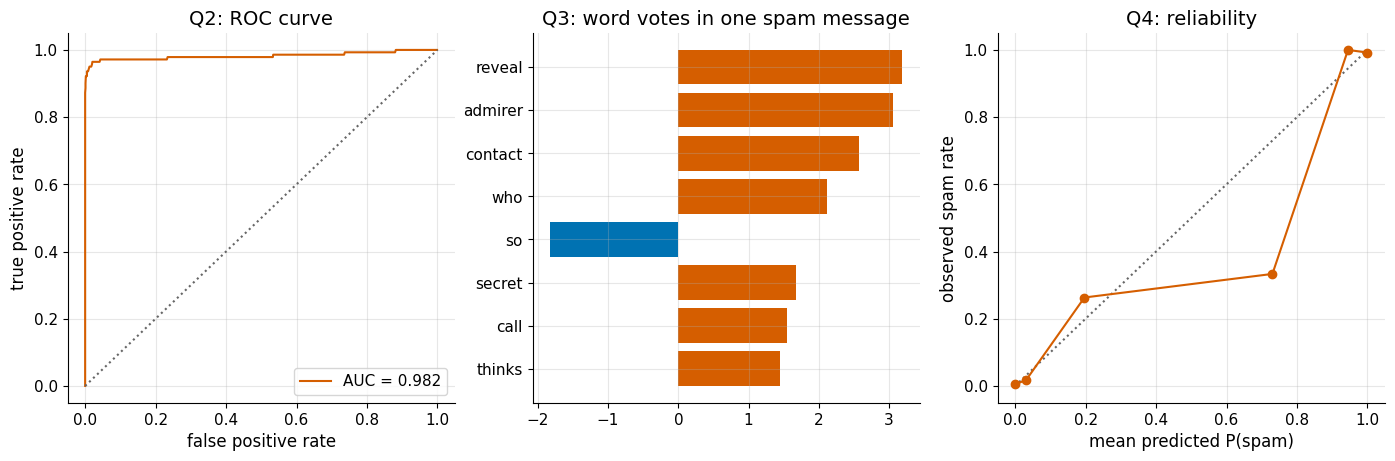

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); thr = np.unique(np.quantile(s_te, np.linspace(0, 1, 400))); tpr = [np.mean(s_te[yte == 1] > t) for t in thr]; fpr = [np.mean(s_te[yte == 0] > t) for t in thr]; axes[0].plot(fpr, tpr, color=HIGHLIGHT, label=f"AUC = {a1:.3f}"); axes[0].plot([0, 1], [0, 1], color=NEUTRAL, linestyle=":"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].legend(); axes[0].set_title("Q2: ROC curve")
contr_o = np.argsort(-np.abs(contrib))[:8]; axes[1].barh([words[k] for k in contr_o][::-1], contrib[contr_o][::-1], color=[HIGHLIGHT if v > 0 else MAIN for v in contrib[contr_o][::-1]]); axes[1].set_title("Q3: word votes in one spam message")
ok = cal["messages"] > 0; axes[2].plot([0, 1], [0, 1], color=NEUTRAL, linestyle=":"); axes[2].plot(cal["mean predicted"][ok], cal["observed spam rate"][ok], "o-", color=HIGHLIGHT); axes[2].set_xlabel("mean predicted P(spam)"); axes[2].set_ylabel("observed spam rate"); axes[2].set_title("Q4: reliability")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- On the 1,115 test messages the filter gives **131 true positives, 5 false positives, 10 false negatives and 969 true negatives**: accuracy **98.65 %** (always "ham" gets 87.35 %), precision **96.3 %**, recall **92.9 %**, F1 **0.946** (bootstrap 95 % interval 0.919 to 0.970). The ROC AUC is **0.982**, and 200,000 random spam-ham pairs give 0.9824: the AUC is the probability that a random spam message outscores a random ham message.
- The votes explain the decisions. The strongest spam words are *claim, prize, won, 150p, tone, 18, £, guaranteed*; the strongest ham words *gt, lt, he, i'll, lor, da, later, she*. For one spam message the prior log-odds are -1.85 and the votes of *reveal* (+3.19), *admirer* (+3.06), *contact* (+2.57), *who* (+2.11) and *secret* (+1.67) outweigh the negative vote of *so* (-1.82): total log-odds **10.69**, $P(\text{spam})\approx1$.
- **The probabilities are not calibrated.** Messages given less than 1 % are spam 0.44 % of the time (mean prediction 0.04 %), those in the 0.50-0.90 band are spam only 33 % of the time (prediction 73 %, 6 messages), and the 127 messages above 0.99 are spam 99.2 % of the time. Mean absolute log-odds is large (18) because correlated words are counted as independent.
- **Decision.** Use the log-odds for ranking and thresholding on validation data, not as literal probabilities; report precision and recall, never accuracy alone.

---
### Example 2: smoothing is a prior (what does $\alpha$ do?)

**Scenario.** The word "prize" appears $N_{\text{prize,spam}}$ times in the spam training messages and $N_{\text{prize,ham}}$ in the ham. We study how its weight, and the whole filter, depend on $\alpha$, and check that the smoothed estimate is the Dirichlet posterior mean.

**Questions.** (1) What are the counts, the unsmoothed weight and the weights for $\alpha=0.1,1,10$? (2) Verify $\hat\theta=(N+\alpha)/(N_c+\alpha V)$ against a Dirichlet posterior simulation. (3) Which $\alpha$ maximises the test F1 and AUC, and what happens with $\alpha=0$ on a word never seen in spam?

In [16]:
j = vocab["prize"]; Ns = m1.fc[1, j]; Nh = m1.fc[0, j]; Cs, Ch = m1.fc[1].sum(), m1.fc[0].sum()
rows = [(a, np.log(((Ns + a) / (Cs + a * V)) / ((Nh + a) / (Ch + a * V)))) for a in (0.01, 0.1, 1, 10, 100)]; print(f"Q1: 'prize': spam count {Ns:.0f} of {Cs:.0f} spam tokens, ham count {Nh:.0f} of {Ch:.0f} ham tokens | unsmoothed weight {np.log((Ns / Cs) / (Nh / Ch)) if Nh > 0 else np.inf:.3f}"); print(pd.DataFrame(rows, columns=["alpha", "weight of 'prize'"]).round(3).to_string(index=False))
g = np.random.default_rng(5); post = g.dirichlet(m1.fc[1] + 1.0, size=20_000)[:, j]; print(f"Q2: Dirichlet posterior mean of theta_prize,spam: simulation {post.mean():.6f}, formula {(Ns + 1) / (Cs + V):.6f}")
res = []
for a in (0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10): mdl = MNB(a).fit(Xtr, ytr); sc = mdl.logodds(Xte); res.append({"alpha": a, **{k: float(v) for k, v in metrics(sc, yte).items() if k in ("accuracy", "precision", "recall", "f1")}, "AUC": auc(sc, yte)})
res = pd.DataFrame(res).set_index("alpha"); print("Q3:"); print(res.round(4).to_string())
unseen = np.where((m1.fc[1] == 0) & (m1.fc[0] > 20))[0][:1]; print("a word never seen in spam but frequent in ham:", words[unseen], "-> with alpha = 0 its weight is -inf (log 0), so a single occurrence forces P(spam) = 0")

Q1: 'prize': spam count 68 of 15272 spam tokens, ham count 0 of 54070 ham tokens | unsmoothed weight inf
 alpha  weight of 'prize'
  0.01             10.087
  0.10              7.770
  1.00              5.343
 10.00              2.600
100.00              0.612


Q2: Dirichlet posterior mean of theta_prize,spam: simulation 0.003614, formula 0.003615
Q3:
        accuracy  precision  recall      f1     AUC
alpha                                              
0.001     0.9865     0.9701  0.9220  0.9455  0.9715
0.010     0.9865     0.9701  0.9220  0.9455  0.9755
0.030     0.9857     0.9630  0.9220  0.9420  0.9786
0.100     0.9857     0.9630  0.9220  0.9420  0.9814
0.300     0.9865     0.9632  0.9291  0.9458  0.9826
1.000     0.9865     0.9632  0.9291  0.9458  0.9823
3.000     0.9848     0.9697  0.9078  0.9377  0.9793
10.000    0.9713     1.0000  0.7730  0.8720  0.9607
a word never seen in spam but frequent in ham: ['abt'] -> with alpha = 0 its weight is -inf (log 0), so a single occurrence forces P(spam) = 0


### 12.6 Asserts

In [17]:
assert abs(post.mean() - (Ns + 1) / (Cs + V)) < 3e-6 and res["f1"].max() > 0.9 and res["f1"].idxmax() <= 1 and res.loc[10, "recall"] < res.loc[0.3, "recall"] and len(unseen) == 1 and rows[0][1] > rows[-1][1]
print("all checks passed")

all checks passed


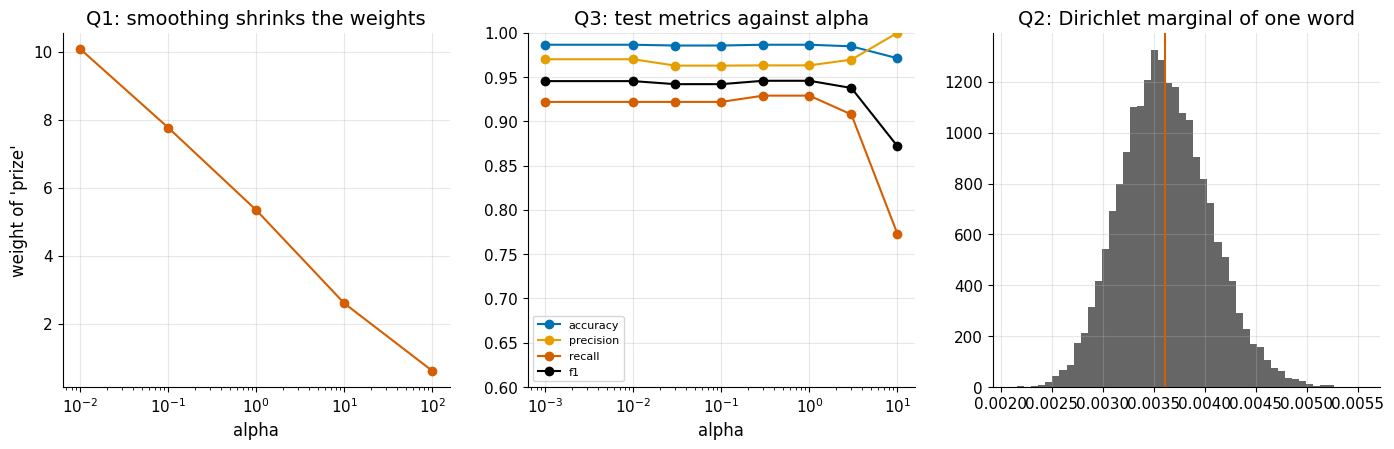

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); axes[0].semilogx([r[0] for r in rows], [r[1] for r in rows], "o-", color=HIGHLIGHT); axes[0].set_xlabel("alpha"); axes[0].set_ylabel("weight of 'prize'"); axes[0].set_title("Q1: smoothing shrinks the weights")
for c_, colr in zip(["accuracy", "precision", "recall", "f1"], [MAIN, SIM, HIGHLIGHT, "black"]): axes[1].semilogx(res.index, res[c_], "o-", color=colr, label=c_)
axes[1].legend(fontsize=8); axes[1].set_xlabel("alpha"); axes[1].set_ylim(0.6, 1); axes[1].set_title("Q3: test metrics against alpha"); axes[2].hist(post, bins=50, color=NEUTRAL); axes[2].axvline((Ns + 1) / (Cs + V), color=HIGHLIGHT); axes[2].set_title("Q2: Dirichlet marginal of one word")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The word "prize" occurs **68 times in the 15,272 spam tokens and never in the 54,070 ham tokens** of the training data: its unsmoothed weight is infinite. Smoothing gives weights of 10.09, 7.77, **5.34**, 2.60 and 0.61 for $\alpha=0.01,0.1,1,10,100$: a larger $\alpha$ shrinks every word's evidence towards zero. The mean of 20,000 Dirichlet posterior draws of $\theta_{\text{prize,spam}}$ is 0.003614 and the formula $(N+1)/(N_c+V)$ gives 0.003615.
- Test performance is flat for $\alpha$ between 0.001 and 1 (F1 0.942 to 0.946, accuracy 98.6 % to 98.65 %, AUC highest at **$\alpha=0.3$: 0.9826**) and degrades for large $\alpha$: at $\alpha=10$ recall falls to **77 %** and F1 to 0.872 because the pseudo-counts drown the real counts. The 3D surface shows the same: with 5 % of the training data (222 messages) the best F1 is 0.858 and with all of it 0.946.
- A word like "abt" is frequent in ham and never in spam; with $\alpha=0$ its weight would be $-\infty$ and one occurrence would force $P(\text{spam})=0$.
- **Decision.** Smooth with $\alpha$ between 0.1 and 1 (tune on validation data); it is a weak Dirichlet prior, not a technical trick.

---
### Example 3: continuous features and a combined model (Gaussian NB + Multinomial NB)

**Scenario.** Besides the words, three numeric features are available for each message: its length in characters, the number of digits and the number of capital letters. A Gaussian naive Bayes uses them. Because naive Bayes assumes independence, the log-odds of two **separate** feature groups can simply be **added** (plus one prior, counted once).

**Questions.** (1) AUC and F1 of Gaussian NB on the three features alone. (2) AUC and F1 of the combined model. (3) How do the number and the kind of errors at threshold 0 change?

In [19]:
caps = np.array([sum(c.isupper() for c in t) for t in texts]); F3 = np.column_stack([ln_, dg, caps]).astype(float); F3tr, F3te = F3[itr], F3[ite]
gm = np.array([F3tr[ytr == c].mean(axis=0) for c in (0, 1)]); gv = np.array([F3tr[ytr == c].var(axis=0) for c in (0, 1)]) + 1e-6
def gnb_score(Fx): ll = np.sum(stats.norm.logpdf(Fx[:, None, :], gm[None], np.sqrt(gv)[None]), axis=2); return ll[:, 1] - ll[:, 0]
sg_te = gnb_score(F3te); lo_g3 = sg_te + pri; comb = s_te + sg_te; r3 = {nm: (auc(s, yte), metrics(s, yte)) for nm, s in [("words (multinomial)", s_te), ("3 numeric features (Gaussian)", lo_g3), ("combined", comb)]}
print(pd.DataFrame({nm: {"AUC": a, "accuracy": m["accuracy"], "precision": m["precision"], "recall": m["recall"], "F1": m["f1"], "errors": m["fp"] + m["fn"]} for nm, (a, m) in r3.items()}).T.round(4).to_string())
print("Gaussian parameters (ham, spam): mean length", gm[:, 0].round(1), "mean digits", gm[:, 1].round(2), "mean capitals", gm[:, 2].round(2))

                                  AUC  accuracy  precision  recall      F1  errors
words (multinomial)            0.9823    0.9865     0.9632  0.9291  0.9458    15.0
3 numeric features (Gaussian)  0.9774    0.9686     0.8630  0.8936  0.8780    35.0
combined                       0.9870    0.9865     0.9437  0.9504  0.9470    15.0
Gaussian parameters (ham, spam): mean length [ 71.4 139. ] mean digits [ 0.3  15.97] mean capitals [ 4.12 15.36]


### 12.7 Asserts

In [20]:
assert r3["combined"][0] > r3["words (multinomial)"][0] - 0.005 and r3["3 numeric features (Gaussian)"][0] > 0.9 and r3["3 numeric features (Gaussian)"][0] < r3["words (multinomial)"][0] and gm[1, 1] > 5 * gm[0, 1]
print("all checks passed")

all checks passed


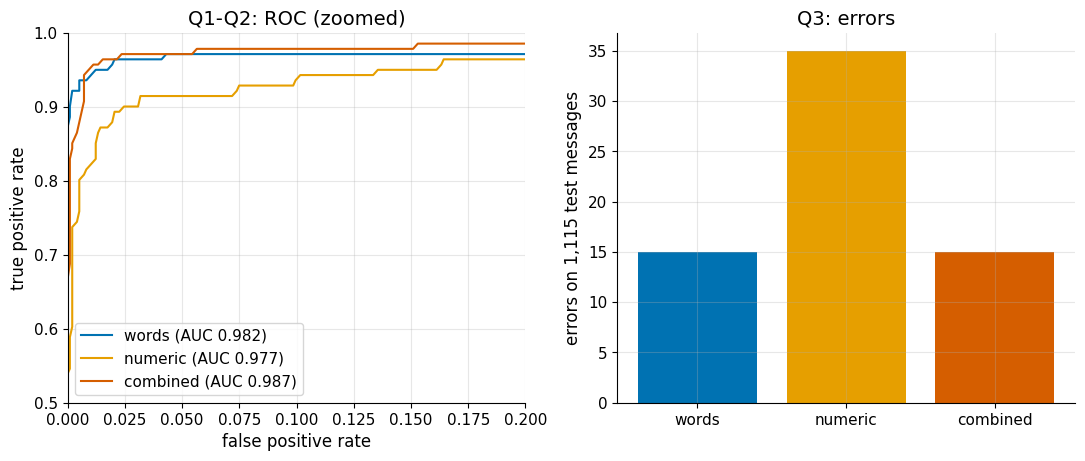

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for nm, s, colr in [("words", s_te, MAIN), ("numeric", lo_g3, SIM), ("combined", comb, HIGHLIGHT)]: thr = np.unique(np.quantile(s, np.linspace(0, 1, 400))); axes[0].plot([np.mean(s[yte == 0] > t) for t in thr], [np.mean(s[yte == 1] > t) for t in thr], color=colr, label=f"{nm} (AUC {auc(s, yte):.3f})")
axes[0].plot([0, 1], [0, 1], color=NEUTRAL, linestyle=":"); axes[0].legend(); axes[0].set_xlim(0, 0.2); axes[0].set_ylim(0.5, 1); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].set_title("Q1-Q2: ROC (zoomed)")
errs = [m["fp"] + m["fn"] for _, (a, m) in r3.items()]; axes[1].bar(["words", "numeric", "combined"], errs, color=[MAIN, SIM, HIGHLIGHT]); axes[1].set_ylabel("errors on 1,115 test messages"); axes[1].set_title("Q3: errors")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- The three numeric features alone reach AUC **0.977** and F1 0.878 (35 errors): spam messages are longer (139 against 71 characters), carry about 16 digits against 0.3, and 15.4 capital letters against 4.1.
- Adding the Gaussian log-odds to the word log-odds raises the AUC from **0.9823 to 0.9870**. At threshold 0 the number of errors is the same (15) but the kind changes: recall rises from 92.9 % to **95.0 %** and precision falls from 96.3 % to 94.4 %: the combined model blocks slightly more real messages and misses fewer spam.
- **Decision.** Combining independent feature groups by adding their log-odds is a cheap way to improve the ranking; set the threshold afterwards (Example 4), because the combined scores are on a different scale.

---
### Example 4: choosing the threshold from the costs of the two errors

**Scenario.** Blocking a real message (false positive) is judged 10 times worse than letting one spam through (false negative). Instead of the default threshold 0, we pick the threshold on a validation part of the training data.

**Questions.** (1) What threshold does Bayes decision theory give if the probabilities were perfectly calibrated? (2) What threshold minimises the cost on a validation set (20 % of the training messages), and what are the test cost, false positive rate and recall at that threshold? (3) How does the cost change with the threshold?

In [22]:
nv = int(0.2 * ntr); pv = np.random.default_rng(6).permutation(ntr); iv, it2 = pv[:nv], pv[nv:]; mv = MNB(1.0).fit(Xtr[it2], ytr[it2]); sv = mv.logodds(Xtr[iv]); yv = ytr[iv]; sT = mv.logodds(Xte)
cost = lambda sc, yy, t: (10 * np.sum((sc > t) & (yy == 0)) + 1 * np.sum((sc <= t) & (yy == 1))) / len(yy); grid = np.linspace(-60, 60, 1201); cv = np.array([cost(sv, yv, t) for t in grid]); t_best = grid[np.argmin(cv)]; t_bayes = np.log(10)
print(f"Q1: with calibrated probabilities the Bayes threshold on the log-odds is ln(10) = {t_bayes:.3f}")
for nm, t in [("default 0", 0.0), ("Bayes ln 10", t_bayes), (f"validation best {t_best:.1f}", t_best)]: m_ = metrics(sT, yte, t); print(f"Q2: threshold {nm}: test cost per message {cost(sT, yte, t):.4f}, false positives {m_['fp']}, false negatives {m_['fn']}, FPR {m_['fpr']:.4f}, recall {m_['recall']:.4f}")
ct = np.array([cost(sT, yte, t) for t in grid])

Q1: with calibrated probabilities the Bayes threshold on the log-odds is ln(10) = 2.303
Q2: threshold default 0: test cost per message 0.0637, false positives 6, false negatives 11, FPR 0.0062, recall 0.9220
Q2: threshold Bayes ln 10: test cost per message 0.0224, false positives 1, false negatives 15, FPR 0.0010, recall 0.8936
Q2: threshold validation best 2.0: test cost per message 0.0206, false positives 1, false negatives 13, FPR 0.0010, recall 0.9078


### 12.9 Asserts

In [23]:
assert cost(sT, yte, t_best) <= cost(sT, yte, 0.0) + 0.002 and metrics(sT, yte, t_best)["fp"] <= metrics(sT, yte, 0.0)["fp"] and abs(t_bayes - 2.302585) < 1e-6
print("all checks passed")

all checks passed


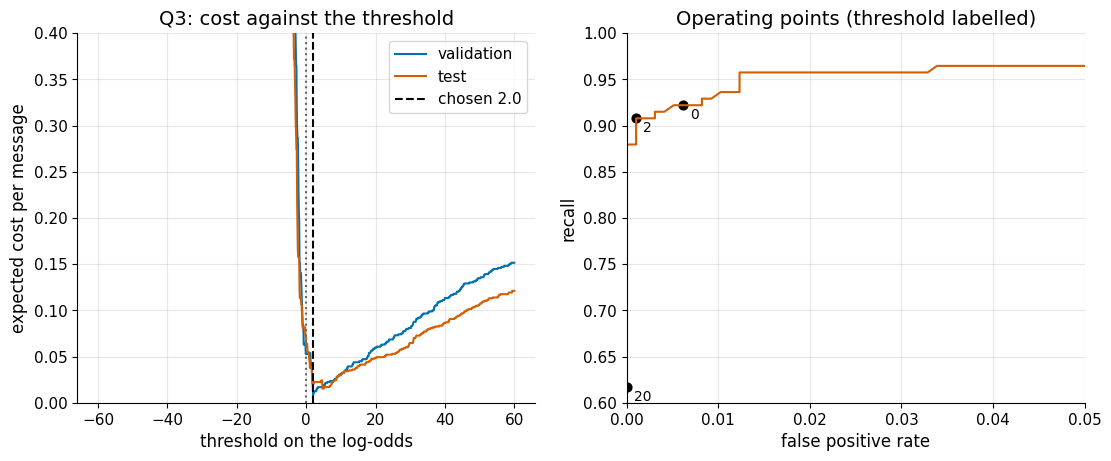

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].plot(grid, cv, color=MAIN, label="validation"); axes[0].plot(grid, ct, color=HIGHLIGHT, label="test"); axes[0].axvline(t_best, color="black", linestyle="--", label=f"chosen {t_best:.1f}"); axes[0].axvline(0, color=NEUTRAL, linestyle=":"); axes[0].set_ylim(0, 0.4); axes[0].set_xlabel("threshold on the log-odds"); axes[0].set_ylabel("expected cost per message"); axes[0].legend(); axes[0].set_title("Q3: cost against the threshold")
ths = [-20, 0, t_best, 20, 40]; axes[1].plot([metrics(sT, yte, t)["fpr"] for t in grid], [metrics(sT, yte, t)["recall"] for t in grid], color=HIGHLIGHT)
for t in ths: m_ = metrics(sT, yte, t); axes[1].scatter([m_["fpr"]], [m_["recall"]], s=40, color="black"); axes[1].annotate(f"{t:.0f}", (m_["fpr"], m_["recall"]), textcoords="offset points", xytext=(5, -10))
axes[1].set_xlim(0, 0.05); axes[1].set_ylim(0.6, 1.0); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("recall"); axes[1].set_title("Operating points (threshold labelled)")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- If the probabilities were calibrated, blocking a real message costing 10 times a missed spam would put the threshold at $\ln10=2.30$. At the default threshold 0 the test cost is **0.0637 per message** (6 false positives, 11 false negatives); at $\ln10$ it is **0.0224** (1 false positive, 15 false negatives, recall 89.4 %); the threshold chosen on a validation set (2.0) gives **0.0206** (1 false positive, 13 false negatives, recall 90.8 %, false positive rate 0.10 %).
- The cost curve is flat around its minimum and rises steeply to the left of it (every extra false positive costs 10), so the exact optimum matters less than staying on the right side.
- **Decision.** Choose the threshold from the costs and validate it on held-out data; a cost-aware threshold cut the cost by about two thirds compared with the default.

## 13. Where it is used

### Statistics
- **Discriminant analysis** and generative classification, **Bayesian networks** (naive Bayes is the simplest one), **likelihood-ratio** decision rules, sequential diagnosis.

### Data science
- **Spam and abuse filters, sentiment and topic classification, document routing,** quick baselines for any high-dimensional count data, **medical decision support** with independent test results, **real-time systems** that update counts online.

### ML and AI
- A baseline for NLP, the **generative-versus-discriminative** comparison with logistic regression, **Gaussian mixtures and EM** (09_04, the same factorisation with hidden classes), the factorised likelihoods behind **VAEs** and **language models**, and feature-weight interpretation (the word votes).

## 14. Common pitfalls and misconceptions

- **Believing the probabilities:** the log-odds are too extreme because correlated features are counted as independent (10.2, Example 1 Q4); use the score for ranking and recalibrate before using probabilities.
- **No smoothing:** an unseen word zeroes a class (Example 2); smooth with $\alpha$ tuned on validation data.
- **Accuracy as the metric on imbalanced data:** "always ham" gets 86.6 %; use precision, recall, F1 and AUC.
- **Using the default threshold:** the optimal threshold depends on the costs and the prevalence (Example 4).
- **Mixing variants:** Multinomial for counts, Bernoulli for presence/absence (it also uses the *absent* words), Gaussian for continuous features; a Gaussian on skewed counts fits poorly.
- **Test leakage:** the vocabulary and the counts must come from the training set only.
- **Adding correlated features:** a second feature that repeats the first double-counts the evidence.

## 15. Exercises

1. Compute the posterior probability of spam for a message whose total log-odds are 1.5, -3 and 8. Which is below the 0.5 line?
2. A class has 200 tokens in total, the word "win" appears 6 times, the vocabulary has 1,000 words. Compute the smoothed probability for $\alpha=1$ and $\alpha=0.1$ and compare with the unsmoothed 3 %.
3. Using the trained model, list the 5 words with the largest positive and the 5 with the most negative weights among words seen at least 30 times.
4. Fit a Bernoulli naive Bayes (presence/absence, $\alpha=1$) on the same split and compare its test F1 and AUC with the multinomial one.
5. What is the test F1 if the vocabulary is restricted to words seen at least 10 times in training?
6. (Harder) Fit a logistic regression (09_02) with the 50 words of largest absolute weight and compare its AUC with naive Bayes using the same 50 words.

Solutions are at the end.

## 16. Summary table

| Item | Formula / value | Note |
|---|---|---|
| Log-odds | prior log-odds $+\sum_jx_j\ln\frac{\theta_{j,s}}{\theta_{j,h}}$ | sum of word votes |
| Smoothed estimate | $(N_{jc}+\alpha)/(N_c+\alpha V)$ | Dirichlet posterior mean |
| Decision | spam if log-odds $>t$ | $t=\ln(C_{FP}/C_{FN})$ if calibrated |
| Gaussian NB | $\sum\ln N(x_j;\mu_{jc},\sigma_{jc}^2)$ | continuous features |
| Metrics | precision, recall, F1, AUC | not accuracy alone |
| Weakness | over-confident probabilities | recalibrate |
| tools | counts, `rankdata`, `logsumexp` | |

## Solutions

In [25]:
print("1: P(spam) for log-odds 1.5, -3, 8:", (1 / (1 + np.exp(-np.array([1.5, -3, 8.0])))).round(4), "(only -3 is below 0.5)")
print(f"2: alpha = 1: {(6 + 1) / (200 + 1000):.5f}; alpha = 0.1: {(6 + 0.1) / (200 + 100):.5f}; unsmoothed {6 / 200:.3f}")
ok30 = np.where(tot >= 30)[0]; print("3: spam:", list(words[ok30[np.argsort(w_[ok30])[::-1][:5]]]), "| ham:", list(words[ok30[np.argsort(w_[ok30])[:5]]]))
Btr = (Xtr > 0).astype(float); Bte = (Xte > 0).astype(float); dc = np.vstack([np.asarray(Btr[ytr == c].sum(axis=0)).ravel() for c in (0, 1)]); pj = (dc + 1) / (np.array([(ytr == 0).sum(), (ytr == 1).sum()])[:, None] + 2)
bern = np.asarray(Bte @ (np.log(pj[1]) - np.log(pj[0]) - np.log(1 - pj[1]) + np.log(1 - pj[0]))).ravel() + np.log(1 - pj[1]).sum() - np.log(1 - pj[0]).sum() + pri; print(f"4: Bernoulli NB: F1 {metrics(bern, yte)['f1']:.4f}, AUC {auc(bern, yte):.4f} | multinomial: F1 {mm['f1']:.4f}, AUC {a1:.4f}")
keep = np.where(m1.fc.sum(axis=0) >= 10)[0]; m10 = MNB(1.0).fit(Xtr[:, keep], ytr); s10 = m10.logodds(Xte[:, keep]); print(f"5: vocabulary of words seen >= 10 times: {len(keep)} words, F1 {metrics(s10, yte)['f1']:.4f}, AUC {auc(s10, yte):.4f}")
sel = np.argsort(-np.abs(w_ * (tot >= 5)))[:50]; Xs_tr = Xtr[:, sel].toarray(); Xs_te = Xte[:, sel].toarray(); m50 = MNB(1.0).fit(sparse.csr_matrix(Xs_tr), ytr); s50 = m50.logodds(sparse.csr_matrix(Xs_te)); b = np.zeros(Xs_tr.shape[1] + 1); XA = np.column_stack([np.ones(len(Xs_tr)), np.log1p(Xs_tr)])
from scipy.special import expit
for _ in range(25): mu_ = expit(XA @ b); W_ = mu_ * (1 - mu_) + 1e-9; b = b + np.linalg.solve(XA.T @ (XA * W_[:, None]) + 1e-3 * np.eye(len(b)), XA.T @ (ytr - mu_))
lr_s = np.column_stack([np.ones(len(Xs_te)), np.log1p(Xs_te)]) @ b; print(f"6: with the same 50 words: naive Bayes AUC {auc(s50, yte):.4f}, logistic regression AUC {auc(lr_s, yte):.4f}")
assert abs((6 + 1) / 1200 - 0.00583) < 1e-4 and auc(bern, yte) > 0.95

1: P(spam) for log-odds 1.5, -3, 8: [0.8176 0.0474 0.9997] (only -3 is below 0.5)
2: alpha = 1: 0.00583; alpha = 0.1: 0.02033; unsmoothed 0.030
3: spam: [np.str_('claim'), np.str_('prize'), np.str_('won'), np.str_('150p'), np.str_('tone')] | ham: [np.str_('gt'), np.str_('lt'), np.str_('he'), np.str_("i'll"), np.str_('lor')]
4: Bernoulli NB: F1 0.9328, AUC 0.9910 | multinomial: F1 0.9458, AUC 0.9823
5: vocabulary of words seen >= 10 times: 935 words, F1 0.9458, AUC 0.9800
6: with the same 50 words: naive Bayes AUC 0.8897, logistic regression AUC 0.8899


**1.** The posterior probabilities are **0.818, 0.047 and 0.9997**: only the message with log-odds -3 is below 0.5.

**2.** $\alpha=1$: $(6+1)/(200+1000)=$ **0.00583**; $\alpha=0.1$: $(6+0.1)/(200+100)=$ **0.0203**; unsmoothed 0.030. Smoothing with a 1,000-word vocabulary shrinks the estimate strongly because the class has only 200 tokens.

**3.** Strongest spam words: *claim, prize, won, 150p, tone*; strongest ham words: *gt, lt, he, i'll, lor*.

**4.** Bernoulli naive Bayes (presence/absence): F1 **0.933**, AUC **0.991** against 0.946 and 0.982 for the multinomial: a slightly worse threshold-0 decision but a better ranking.

**5.** With the 935 words seen at least 10 times the F1 is **0.946** (AUC 0.980): dropping the rare words costs nothing.

**6.** With only the 50 words of largest weight both models are much weaker: AUC **0.890** for naive Bayes and **0.890** for logistic regression: with so few features the two methods are equivalent.